**Q5. Use Naive bayes, K-nearest, and Decision tree classification algorithms and build classifiers. Divide the data set into training and test set.** **Compare the accuracy of the different classifiers under the following situations:**

5.1       a) Training set = 75% Test set = 25%  
b) Training set = 66.6% (2/3rd of total), Test set = 33.3% (Student Task)

5.2 Training set is chosen by <br>
i) Hold out method <br>
ii) Random subsampling <br>
iii) Cross-Validation. <br>Compare the accuracy of the classifiers obtained. 

5.3 Data is scaled to standard format.


**Hold out method - Decision Tree- (IRIS Dataset)**

In [1]:
# import the necessary libraries:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris

In [2]:
iris=load_iris()
X=iris.data
Y=iris.target

In [3]:
iris_df= pd.DataFrame(X, columns=iris.feature_names)

In [4]:
iris_df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [5]:
iris_df["class"]=Y

In [6]:
iris_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   class              150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [7]:
iris_df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [8]:
iris_df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
class                0
dtype: int64

In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler() 

In [10]:
scaled_iris=scaler.fit_transform(iris_df.iloc[:, :-1])

In [11]:
X=pd.DataFrame(scaled_iris, columns=iris.feature_names)

In [12]:
X.head(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444


In [13]:
from sklearn.model_selection import train_test_split

**Training set= 75%, test set=25%**

In [14]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.25, random_state=1)

In [15]:
X_train.shape

(112, 4)

In [16]:
X_test.shape

(38, 4)

In [17]:
Y_train.shape

(112,)

In [18]:
Y_test.shape

(38,)

In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

In [20]:
dec_tree = DecisionTreeClassifier(criterion = 'entropy')


In [21]:
dec_tree.fit(X_train, Y_train)

DecisionTreeClassifier(criterion='entropy')

In [22]:
prediction = dec_tree.predict(X_test)

In [23]:
prediction

array([0, 1, 1, 0, 2, 1, 2, 0, 0, 2, 1, 0, 2, 1, 1, 0, 1, 1, 0, 0, 1, 1,
       2, 0, 2, 1, 0, 0, 1, 2, 1, 2, 1, 2, 2, 0, 1, 0])

[Text(0.4, 0.9166666666666666, 'x[3] <= -0.526\nentropy = 1.581\nsamples = 112\nvalue = [37, 34, 41]'),
 Text(0.3, 0.75, 'entropy = 0.0\nsamples = 37\nvalue = [37, 0, 0]'),
 Text(0.35, 0.8333333333333333, 'True  '),
 Text(0.5, 0.75, 'x[3] <= 0.593\nentropy = 0.994\nsamples = 75\nvalue = [0, 34, 41]'),
 Text(0.45, 0.8333333333333333, '  False'),
 Text(0.2, 0.5833333333333334, 'x[2] <= 0.678\nentropy = 0.494\nsamples = 37\nvalue = [0, 33, 4]'),
 Text(0.1, 0.4166666666666667, 'entropy = 0.0\nsamples = 32\nvalue = [0, 32, 0]'),
 Text(0.3, 0.4166666666666667, 'x[0] <= 0.25\nentropy = 0.722\nsamples = 5\nvalue = [0, 1, 4]'),
 Text(0.2, 0.25, 'x[2] <= 0.734\nentropy = 1.0\nsamples = 2\nvalue = [0, 1, 1]'),
 Text(0.1, 0.08333333333333333, 'entropy = 0.0\nsamples = 1\nvalue = [0, 0, 1]'),
 Text(0.3, 0.08333333333333333, 'entropy = 0.0\nsamples = 1\nvalue = [0, 1, 0]'),
 Text(0.4, 0.25, 'entropy = 0.0\nsamples = 3\nvalue = [0, 0, 3]'),
 Text(0.8, 0.5833333333333334, 'x[2] <= 0.621\nentropy = 0.1

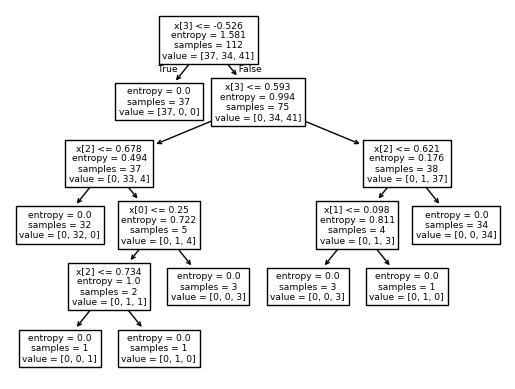

In [24]:
tree.plot_tree(dec_tree)

In [25]:
import matplotlib.pyplot as plt
from sklearn import metrics

In [26]:
fn= iris.feature_names

In [27]:
fn

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [28]:
cn=['setosa', 'versicolor', 'verginica'] # class names

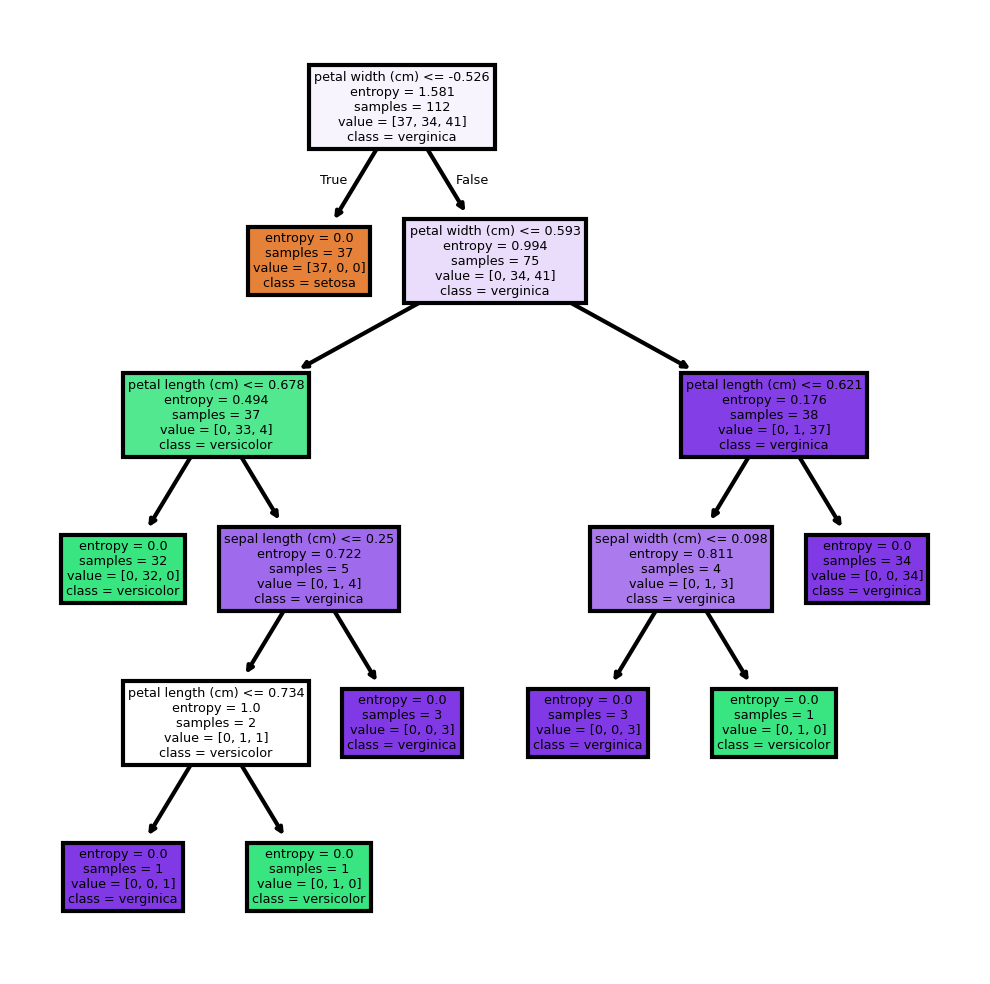

In [29]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(4,4), dpi=300)
tree.plot_tree(dec_tree, feature_names=fn, class_names=cn, filled=True);

In [30]:
from sklearn import metrics
from sklearn.metrics import ConfusionMatrixDisplay

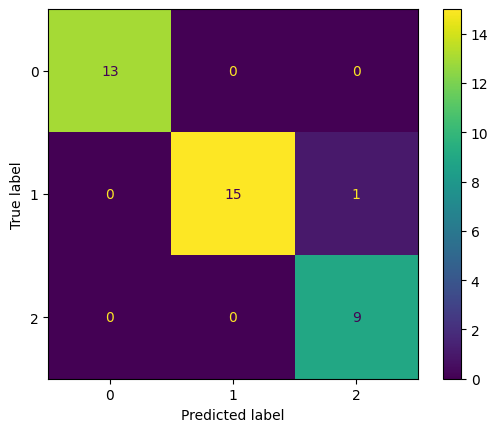

In [31]:
ConfusionMatrixDisplay.from_estimator(dec_tree, X_test, Y_test)

In [32]:
accuracy_dt=metrics.accuracy_score(Y_test, prediction)*100

In [33]:
print("Accuracy: ", accuracy_dt)

Accuracy:  97.36842105263158


In [34]:
print("Classifiaction Report: \n", metrics.classification_report(Y_test, prediction))

Classifiaction Report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        13
           1       1.00      0.94      0.97        16
           2       0.90      1.00      0.95         9

    accuracy                           0.97        38
   macro avg       0.97      0.98      0.97        38
weighted avg       0.98      0.97      0.97        38



**Hold out method - KNN- (IRIS Dataset)**

In [35]:
from sklearn.neighbors import KNeighborsClassifier

In [36]:
knn= KNeighborsClassifier()

In [37]:
knn.fit(X_train, Y_train)

KNeighborsClassifier()

In [38]:
prediction2=knn.predict(X_test)

In [39]:
prediction2

array([0, 1, 1, 0, 2, 1, 2, 0, 0, 2, 1, 0, 2, 1, 1, 0, 1, 1, 0, 0, 1, 1,
       2, 0, 2, 1, 0, 0, 1, 2, 1, 2, 1, 2, 2, 0, 1, 0])

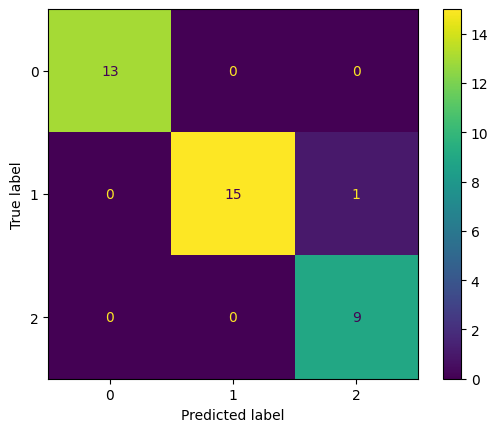

In [40]:
ConfusionMatrixDisplay.from_estimator(knn, X_test, Y_test)

In [41]:
accuracy_knn=metrics.accuracy_score(Y_test, prediction2)*100

In [42]:
accuracy_knn

97.36842105263158

In [43]:
print("Accuracy: ", accuracy_knn)

Accuracy:  97.36842105263158


In [44]:
print("Classifiaction Report: \n", metrics.classification_report(Y_test, prediction2))

Classifiaction Report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        13
           1       1.00      0.94      0.97        16
           2       0.90      1.00      0.95         9

    accuracy                           0.97        38
   macro avg       0.97      0.98      0.97        38
weighted avg       0.98      0.97      0.97        38



**Hold out method - Naive Bayes- (IRIS Dataset)**

In [45]:
from sklearn.naive_bayes import GaussianNB

In [46]:
nb= GaussianNB() 

In [47]:
nb.fit(X_train,Y_train)

GaussianNB()

In [48]:
prediction_nb=nb.predict(X_test)

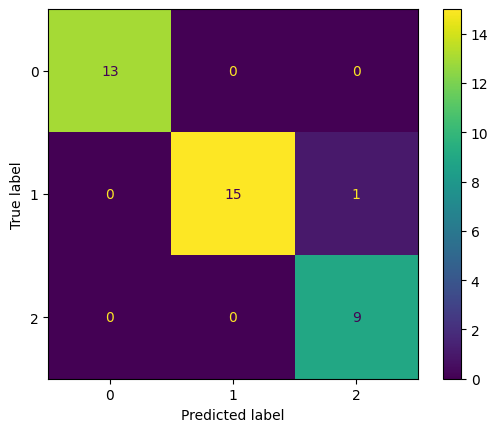

In [49]:
ConfusionMatrixDisplay.from_estimator(nb, X_test, Y_test)

In [50]:
accuracy_nb=metrics.accuracy_score(Y_test, prediction_nb)*100

In [51]:
print("Naive Bayes Accuracy: ", accuracy_nb)
print("Classifiaction Report: \n", metrics.classification_report(Y_test, prediction_nb))

Naive Bayes Accuracy:  97.36842105263158
Classifiaction Report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        13
           1       1.00      0.94      0.97        16
           2       0.90      1.00      0.95         9

    accuracy                           0.97        38
   macro avg       0.97      0.98      0.97        38
weighted avg       0.98      0.97      0.97        38



**Random Subsampling - Decision Tree- (IRIS Dataset)**

In [52]:
acc=[]
dec_tree = DecisionTreeClassifier(criterion= 'entropy')
for i in range(10):
    X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.25,random_state = i+1)

    dec_tree.fit(X_train, Y_train)
    prediction=dec_tree.predict(X_test)
    acc.append(metrics.accuracy_score(Y_test, prediction))

acc = sum(acc) / len(acc)
acc_rs_iris_dt = acc*100
print("Accuracy on the test data", acc_rs_iris_dt, "%")

Accuracy on the test data 94.73684210526315 %


**Random Subsampling - KNN- (IRIS Dataset)**

In [53]:
acc=[]
knn = KNeighborsClassifier()
for i in range(10):
    X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.25,random_state = i+1)
    knn.fit(X_train, Y_train)
    prediction2=knn.predict(X_test)
    acc.append(metrics.accuracy_score(Y_test, prediction2))

acc = sum(acc) / len(acc)
acc_rs_iris_knn = acc*100
print("Accuracy on the test data", acc_rs_iris_knn, "%")

Accuracy on the test data 95.26315789473685 %


**Random Subsampling - Naive Bayes- (IRIS Dataset)**

In [54]:
acc=[]
nb = GaussianNB()
for i in range(10):
    X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.25,random_state = i+1)
    nb.fit(X_train, Y_train)
    prediction3=nb.predict(X_test)
    acc.append(metrics.accuracy_score(Y_test, prediction3))

acc = sum(acc) / len(acc)
acc_rs_iris_nb = acc*100
print("Accuracy on the test data", acc_rs_iris_nb, "%")

Accuracy on the test data 94.73684210526315 %


**Cross Validation - Decision Tree- (IRIS Dataset)**

In [62]:
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
dec_tree = DecisionTreeClassifier(criterion= 'entropy')
score1= cross_val_score(dec_tree, X, Y, cv=4)
acc_cv_iris_dt=score1.mean()*100
print("Accuracy of the test data", acc_cv_iris_dt, "%")


Accuracy of the test data 96.67496443812233 %


**Cross Validation - KNN- (IRIS Dataset)**

In [56]:
knn = KNeighborsClassifier()
score2= cross_val_score(knn, X, Y, cv=4)
acc_cv_iris_knn=score2.mean()*100
print("Accuracy of the test data", acc_cv_iris_knn, "%")

Accuracy of the test data 94.66571834992888 %


**Cross Validation - Naive Bayes- (IRIS Dataset)**

In [57]:
nb = GaussianNB()
score3= cross_val_score(nb, X, Y, cv=4)
acc_cv_iris_nb=score3.mean()*100
print("Accuracy of the test data", acc_cv_iris_nb, "%")

Accuracy of the test data 95.34139402560456 %


**RESULTS**

**Holdout Method**

In [59]:
print("Accuracy of Decision Tree Model on Iris Data using Holdout Method: ", accuracy_dt)
print("Accuracy of KNN Model on Iris Data using Holdout Method: ", accuracy_knn)
print("Accuracy of Naive Bayes Model on Iris Data using Holdout Method: ", accuracy_nb)

Accuracy of Decision Tree Model on Iris Data using Holdout Method:  97.36842105263158
Accuracy of KNN Model on Iris Data using Holdout Method:  97.36842105263158
Accuracy of Naive Bayes Model on Iris Data using Holdout Method:  97.36842105263158


**Random Subsampling**

In [60]:
print("Accuracy of Decision Tree Model on Iris Data using Random Subsampling Method: ", acc_rs_iris_dt)
print("Accuracy of KNN Model on Iris Data using Random Subsampling Method: ", acc_rs_iris_knn)
print("Accuracy of Naive Bayes Model on Iris Data using Random Subsampling Method: ", acc_rs_iris_nb)

Accuracy of Decision Tree Model on Iris Data using Random Subsampling Method:  94.73684210526315
Accuracy of KNN Model on Iris Data using Random Subsampling Method:  95.26315789473685
Accuracy of Naive Bayes Model on Iris Data using Random Subsampling Method:  94.73684210526315


**Cross Validation**

In [61]:
print("Accuracy of Decision Tree Model on Iris Data using Cross Validation Method: ", acc_cv_iris_dt)
print("Accuracy of KNN Model on Iris Data using Cross Validation Method: ", acc_cv_iris_knn)
print("Accuracy of Naive Bayes Model on Iris Data using Cross Validation Method: ", acc_cv_iris_nb)

Accuracy of Decision Tree Model on Iris Data using Cross Validation Method:  96.67496443812233
Accuracy of KNN Model on Iris Data using Cross Validation Method:  94.66571834992888
Accuracy of Naive Bayes Model on Iris Data using Cross Validation Method:  95.34139402560456


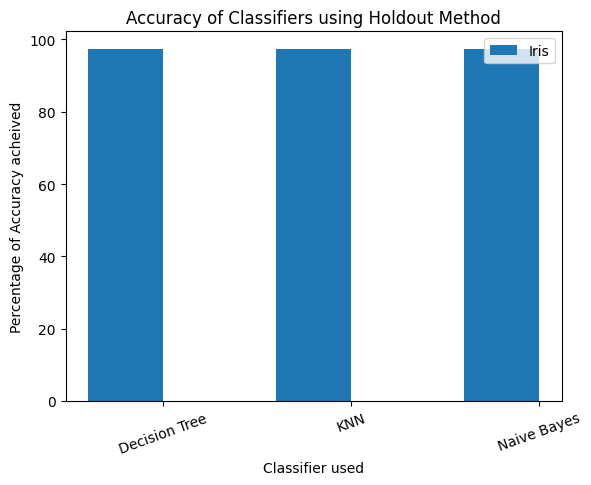

In [67]:
import matplotlib.pyplot as plt
X= ['Decision Tree', 'KNN','Naive Bayes']
Y_iris=[accuracy_dt, accuracy_knn, accuracy_nb]
X_axis=np.arange(len(X))
plt.bar(X_axis - 0.2, Y_iris, 0.4, label="Iris")
plt.xlabel("Classifier used")
plt.ylabel("Percentage of Accuracy acheived")
plt.title("Accuracy of Classifiers using Holdout Method")
plt.xticks(X_axis, X, rotation = 20)
plt.legend()
plt.show()

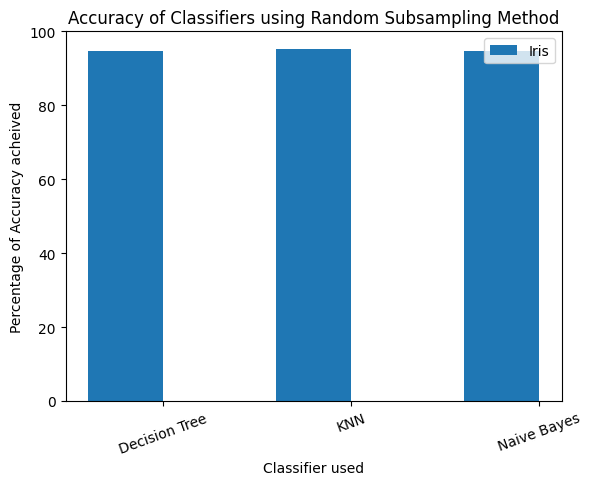

In [68]:
import matplotlib.pyplot as plt
X= ['Decision Tree', 'KNN','Naive Bayes']
Y_iris=[acc_rs_iris_dt, acc_rs_iris_knn, acc_rs_iris_nb]
X_axis=np.arange(len(X))
plt.bar(X_axis - 0.2, Y_iris, 0.4, label="Iris")
plt.xlabel("Classifier used")
plt.ylabel("Percentage of Accuracy acheived")
plt.title("Accuracy of Classifiers using Random Subsampling Method")
plt.xticks(X_axis, X, rotation = 20)
plt.legend()
plt.show()

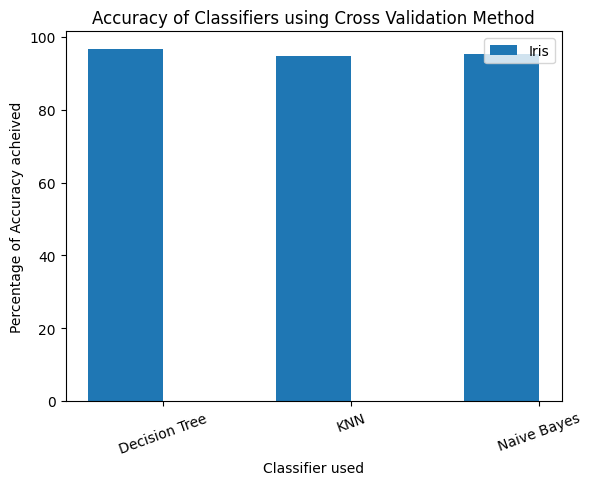

In [71]:
import matplotlib.pyplot as plt
X= ['Decision Tree', 'KNN','Naive Bayes']
Y_iris=[acc_cv_iris_dt, acc_cv_iris_knn, acc_cv_iris_nb]
X_axis=np.arange(len(X))
plt.bar(X_axis - 0.2, Y_iris, 0.4, label="Iris")
plt.xlabel("Classifier used")
plt.ylabel("Percentage of Accuracy acheived")
plt.title("Accuracy of Classifiers using Cross Validation Method")
plt.xticks(X_axis, X, rotation = 20)
plt.legend()
plt.show()